# 🧠 Simple IHM: análise dos modelos de falha

Este notebook mostra **como** os modelos de falha foram construídos e **por que** cada escolha foi feita. Ele usa exatamente as mesmas funções do script de treino (`python -m ml.treinar`), com a mesma semente, então os números aqui são os do modelo salvo em `ml/modelos/`.

O sistema responde três perguntas:

| Pergunta | Técnica | Saída |
|---|---|---|
| **1. Detecção:** a máquina está fora do padrão? | Isolation Forest | Alerta de anomalia |
| **2. Diagnóstico:** que falha é? | Árvore de decisão | Tipo da falha e confiança |
| **3. Prognóstico:** quando passa do limite? | Regressão linear (com termo quadrático) | Minutos até o limite de vibração |

**Para reproduzir:**

```bash
pip install -r ml/requirements.txt
python -m simulador.gerar_dataset      # gera ml/dados/dataset.csv
python -m ml.treinar                   # treina e salva o modelo
```

Os gráficos também são salvos em `ml/figuras/`, prontos para os slides.

In [1]:
import os
import sys
from pathlib import Path

# Funciona aberto tanto da raiz do repositório quanto da pasta ml/
RAIZ = Path.cwd() if (Path.cwd() / "ml").is_dir() else Path.cwd().parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.tree import export_text, plot_tree

from ml import treinar
from ml.avaliacao import (
    avaliar_deteccao,
    avaliar_diagnostico,
    avaliar_prognostico,
    normal_limpo,
    preparar_dados,
)
from ml.features import COLUNAS_DETECTOR, COLUNAS_DIAGNOSTICO, LEITURAS_POR_MINUTO
from ml.modelo import LimiaresEstatisticos, ModeloFalhas, confirmar
from ml.tendencia import ajustar_tendencia, _termos

FIGURAS = Path("ml/figuras")
FIGURAS.mkdir(parents=True, exist_ok=True)

CORES = {
    "normal": "#9e9e9e",
    "desgaste_rolamento": "#E69F00",
    "sobrecarga": "#D55E00",
    "queda_tensao": "#0072B2",
    "desbalanceamento": "#CC79A7",
}
NOMES = {
    "normal": "Normal",
    "desgaste_rolamento": "Desgaste de rolamento",
    "sobrecarga": "Sobrecarga",
    "queda_tensao": "Queda de tensão",
    "desbalanceamento": "Desbalanceamento",
}
FALHAS = [c for c in NOMES if c != "normal"]

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 10,
    }
)
pd.set_option("display.precision", 3)


def salvar(fig, nome):
    fig.savefig(FIGURAS / f"{nome}.png")

## 1. Os dados

O dataset vem do **gerador offline** do simulador (`python -m simulador.gerar_dataset`): 6 sessões de 12 horas, 4 máquinas, uma leitura a cada 2 segundos. Falhas são disparadas em momentos aleatórios, com **tipo, intensidade (0,5× a 1,5×) e duração sorteados**, e de 10 a 30 minutos de operação normal entre elas.

Cada linha traz o **rótulo verdadeiro** (`cenario`), que uma ESP32 real nunca saberia. É ele que permite treinar e, principalmente, medir se o modelo acerta.

In [3]:
bruto = pd.read_csv("ml/dados/dataset.csv")
dados = preparar_dados(bruto)

resumo = (
    pd.DataFrame(
        {
            "leituras": dados["cenario"].value_counts(),
            "ocorrências": dados[dados["evento"] >= 0]
            .groupby("cenario")["evento"]
            .nunique(),
        }
    )
    .rename(index=NOMES)
    .fillna(0)
    .astype(int)
)
resumo["% do tempo"] = (resumo["leituras"] / resumo["leituras"].sum() * 100).round(1)
print(
    f"{len(dados):,} leituras · {dados['sessao'].nunique()} sessões · {dados['maquina_id'].nunique()} máquinas"
)
resumo

518,400 leituras · 6 sessões · 4 máquinas


,leituras,ocorrências,% do tempo
cenario,,,
Desbalanceamento,12640,188,2.4
Desgaste de rolamento,30610,192,5.9
Normal,467002,0,90.1
Queda de tensão,4878,188,0.9
Sobrecarga,3270,196,0.6


A sobrecarga tem poucas **linhas** (dura ~30 s), mas um número de **ocorrências** parecido com o das outras falhas. Por isso todas as métricas daqui em diante são **por ocorrência de falha**, e não por linha: o que importa para a manutenção é se cada falha foi pega, e quando.

### Como as falhas aparecem nos sinais

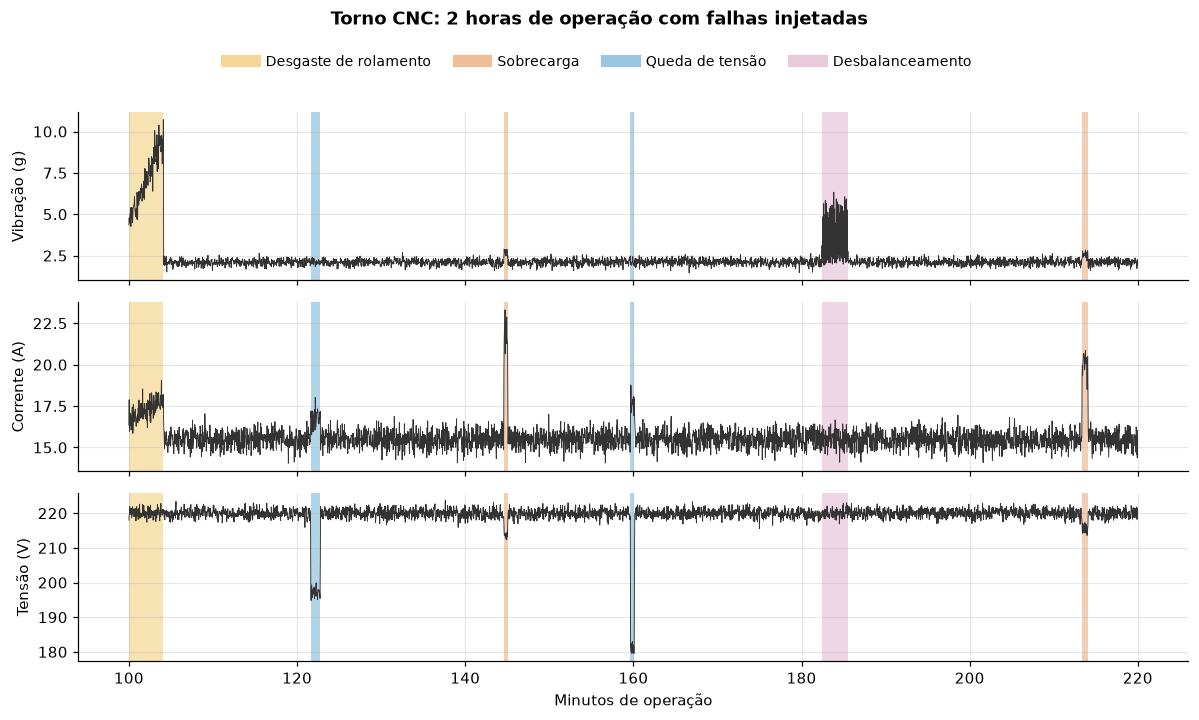

In [4]:
sessao = sorted(dados["sessao"].unique())[-1]
trecho = dados[(dados["sessao"] == sessao) & (dados["maquina_id"] == 1)].iloc[3000:6600]
minutos = trecho["posicao"].to_numpy() / LEITURAS_POR_MINUTO

fig, eixos = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
for eixo, (coluna, rotulo) in zip(
    eixos,
    [
        ("vibracao_rms", "Vibração (g)"),
        ("corrente_ampere", "Corrente (A)"),
        ("tensao_volt", "Tensão (V)"),
    ],
):
    eixo.plot(minutos, trecho[coluna], lw=0.6, color="#333")
    eixo.set_ylabel(rotulo)
    for _, ev in trecho[trecho["evento"] >= 0].groupby("evento"):
        m = ev["posicao"].to_numpy() / LEITURAS_POR_MINUTO
        eixo.axvspan(m[0], m[-1], color=CORES[ev["cenario"].iat[0]], alpha=0.3, lw=0)
eixos[-1].set_xlabel("Minutos de operação")
for falha in FALHAS:
    eixos[0].plot([], [], color=CORES[falha], lw=8, alpha=0.4, label=NOMES[falha])
fig.legend(
    loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=4, fontsize=9, frameon=False
)
fig.suptitle(
    "Torno CNC: 2 horas de operação com falhas injetadas", fontweight="bold", y=1.0
)
fig.tight_layout(rect=(0, 0, 1, 0.93))
salvar(fig, "01_sinais")

Cada falha deixa uma "assinatura" diferente: o desgaste faz a vibração **subir aos poucos**, a sobrecarga dá um **salto de corrente**, a queda de tensão derruba a **tensão**, e o desbalanceamento faz a vibração **oscilar**.

## 2. Features: comparar cada máquina com ela mesma

Uma leitura isolada é ruidosa demais, e um valor absoluto não diz nada (5,8 g é normal numa injetora e alarmante numa prensa). Por isso cada leitura vira **15 features** calculadas em janelas, sempre em relação à **linha de base da própria máquina** (mediana dos últimos 30 min):

- **desvio:** média dos últimos 30 s em relação ao normal (+0,5 = 50% acima);
- **ruído:** oscilação dos últimos 30 s em relação ao normal;
- **tendência:** inclinação da reta dos últimos 3 min (variação por minuto).

…para tensão, corrente, potência, vibração e frequência. As features só usam leituras passadas, e há um teste automático garantindo isso (`tests/unit/test_ml_features.py`).

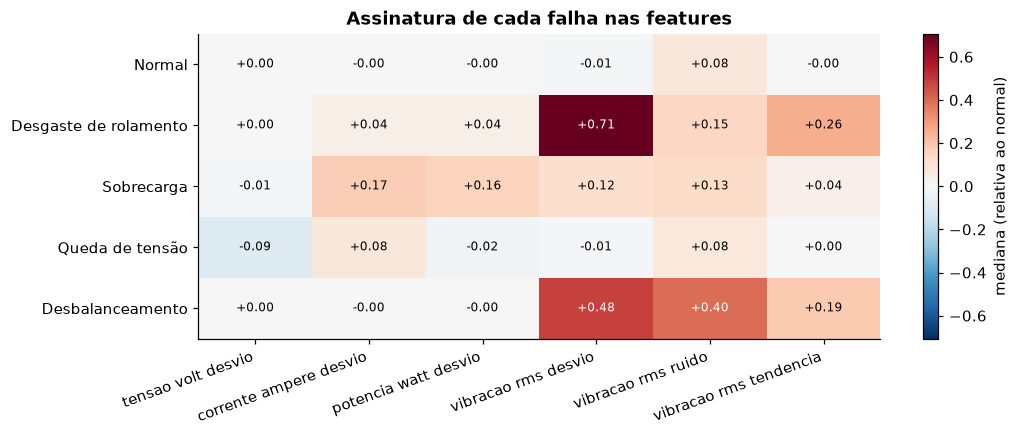

In [5]:
assinatura = (
    dados[dados["valido"] & ((dados["evento"] >= 0) | normal_limpo(dados))]
    .groupby("cenario")[list(COLUNAS_DIAGNOSTICO)]
    .median()
    .loc[list(NOMES)]
)
destaque = [
    "tensao_volt_desvio",
    "corrente_ampere_desvio",
    "potencia_watt_desvio",
    "vibracao_rms_desvio",
    "vibracao_rms_ruido",
    "vibracao_rms_tendencia",
]

fig, eixo = plt.subplots(figsize=(10, 3.6))
valores = assinatura[destaque].to_numpy()
limite = np.abs(valores).max()
imagem = eixo.imshow(valores, cmap="RdBu_r", vmin=-limite, vmax=limite, aspect="auto")
eixo.set_xticks(
    range(len(destaque)),
    [c.replace("_", " ") for c in destaque],
    rotation=20,
    ha="right",
)
eixo.set_yticks(range(len(assinatura)), [NOMES[c] for c in assinatura.index])
for (i, j), v in np.ndenumerate(valores):
    eixo.text(
        j,
        i,
        f"{v:+.2f}",
        ha="center",
        va="center",
        fontsize=8,
        color="white" if abs(v) > limite * 0.55 else "black",
    )
eixo.grid(False)
fig.colorbar(imagem, ax=eixo, label="mediana (relativa ao normal)")
eixo.set_title("Assinatura de cada falha nas features", fontweight="bold")
salvar(fig, "02_assinaturas")

## 3. Treino e teste separados por sessão

As últimas 2 sessões ficam **só para teste**. Separar por sessão, e não sorteando linhas, é essencial: leituras vizinhas são quase idênticas, e sortear linhas deixaria pedaços da mesma falha no treino e no teste, inflando o resultado.

Também ficam fora do treino os **3 minutos depois de cada falha** (*transição*): o rótulo já é "normal", mas as janelas ainda contêm a falha.

In [6]:
treino, teste = treinar.dividir_por_sessao(dados)
dados_teste = dados[teste & dados["valido"]].reset_index(drop=True)

print("Treino:", sorted(dados.loc[treino, "sessao"].unique()))
print("Teste: ", sorted(dados.loc[teste, "sessao"].unique()))
print(
    f"Falhas no teste: {dados_teste.loc[dados_teste['evento'] >= 0, 'evento'].nunique()}"
)

Treino: ['offline-s42-01', 'offline-s42-02', 'offline-s42-03', 'offline-s42-04']
Teste:  ['offline-s42-05', 'offline-s42-06']
Falhas no teste: 261


## 4. Detecção: está fora do padrão?

O detector é uma **Isolation Forest** treinada **só com operação normal**. Ela não precisa de exemplos de falha: aprende como o normal se parece e estranha o resto. Por isso também acusaria um tipo de falha que nunca foi simulado.

Para saber se o ML vale a pena, ela é comparada com uma **linha de base sem ML**: limites fixos em cada feature, no quantil 99,9% da operação normal (o que um engenheiro faria "na mão").

Nos dois casos, um alerta só é confirmado depois de **5 leituras seguidas (10 s)** de anomalia.

In [7]:
X_normal = dados.loc[treino & treinar.linhas_detector(dados), list(COLUNAS_DETECTOR)]
detector, limiar = treinar.treinar_detector(X_normal)
limiares = LimiaresEstatisticos().fit(X_normal)

filtro = treino & treinar.linhas_diagnostico(dados)
arvore = treinar.treinar_diagnostico(
    dados.loc[filtro, list(COLUNAS_DIAGNOSTICO)], dados.loc[filtro, "cenario"]
)

modelo = ModeloFalhas(
    detector=detector,
    limiar_detector=limiar,
    diagnostico=arvore,
    leituras_confirmacao=treinar.LEITURAS_CONFIRMACAO,
    limite_vibracao=treinar.LIMITE_VIBRACAO,
)


def confirmar_por_maquina(brutos, leituras):
    alertas = np.zeros(len(dados_teste), dtype=bool)
    for indices in dados_teste.groupby(
        ["sessao", "maquina_id"], sort=False
    ).indices.values():
        alertas[indices] = confirmar(brutos[indices], leituras)
    return alertas


brutos = {
    "Limites fixos (sem ML)": limiares.detectar(dados_teste[list(COLUNAS_DETECTOR)]),
    "Isolation Forest": modelo.detectar(dados_teste),
}
resultados, eventos = {}, {}
for nome, b in brutos.items():
    resultados[nome], eventos[nome] = avaliar_deteccao(
        dados_teste, confirmar_por_maquina(b, treinar.LEITURAS_CONFIRMACAO)
    )

pd.DataFrame(
    {
        nome: {
            "falhas detectadas": f"{r['taxa_deteccao']:.1%}",
            "atraso mediano (s)": r["atraso_mediano_s"],
            "alarmes falsos por máquina-dia": round(
                r["alarmes_falsos_por_maquina_dia"], 2
            ),
        }
        for nome, r in resultados.items()
    }
).T

,falhas detectadas,atraso mediano (s),alarmes falsos por máquina-dia
Limites fixos (sem ML),99.6%,10.0,26.48
Isolation Forest,99.6%,12.0,0.66


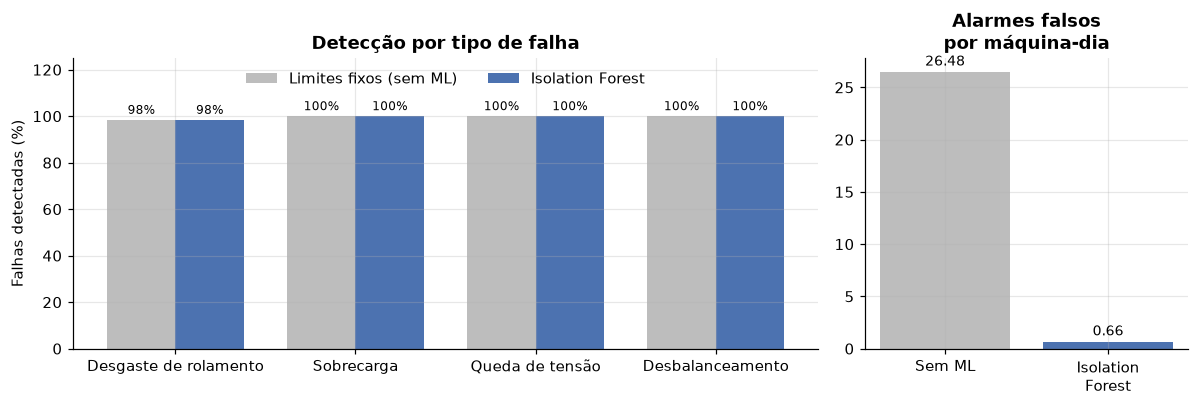

In [8]:
fig, (a, b) = plt.subplots(
    1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 1.3]}
)
largura = 0.38
x = np.arange(len(FALHAS))
for i, (nome, r) in enumerate(resultados.items()):
    taxas = [r["por_cenario"][f]["taxa_deteccao"] * 100 for f in FALHAS]
    barras = a.bar(
        x + (i - 0.5) * largura,
        taxas,
        largura,
        label=nome,
        color=["#bdbdbd", "#4c72b0"][i],
    )
    a.bar_label(barras, fmt="%.0f%%", fontsize=8, padding=2)
a.set_xticks(x, [NOMES[f] for f in FALHAS])
a.set_ylabel("Falhas detectadas (%)")
a.set_ylim(0, 125)
a.legend(frameon=False, loc="upper center", ncol=2)
a.set_title("Detecção por tipo de falha", fontweight="bold")

falsos = [r["alarmes_falsos_por_maquina_dia"] for r in resultados.values()]
barras = b.bar(["Sem ML", "Isolation\nForest"], falsos, color=["#bdbdbd", "#4c72b0"])
b.bar_label(barras, fmt="%.2f", fontsize=9, padding=2)
b.set_title("Alarmes falsos\npor máquina-dia", fontweight="bold")
fig.tight_layout()
salvar(fig, "03_deteccao")

### Quantas leituras exigir antes de alertar?

Exigir mais leituras seguidas reduz alarmes falsos, mas atrasa a detecção. O gráfico mostra a troca; 5 leituras (10 s) ficou no ponto em que os alarmes falsos já caíram e o atraso ainda é pequeno.

,detecção (%),atraso mediano (s),alarmes falsos/máquina-dia
leituras,,,
1,99.62,4.0,19.20
2,99.62,6.0,7.28
3,99.62,8.0,2.98
5,99.62,12.0,0.66
8,99.62,18.0,0.00
12,99.62,26.0,0.00
20,97.70,42.0,0.00


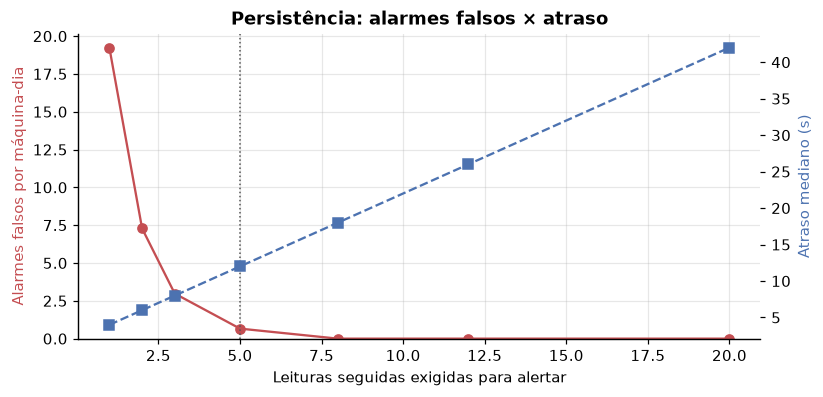

In [9]:
linhas = []
for leituras in (1, 2, 3, 5, 8, 12, 20):
    r, _ = avaliar_deteccao(
        dados_teste, confirmar_por_maquina(brutos["Isolation Forest"], leituras)
    )
    linhas.append(
        {
            "leituras": leituras,
            "detecção (%)": r["taxa_deteccao"] * 100,
            "atraso mediano (s)": r["atraso_mediano_s"],
            "alarmes falsos/máquina-dia": r["alarmes_falsos_por_maquina_dia"],
        }
    )
persistencia = pd.DataFrame(linhas).set_index("leituras")

fig, eixo = plt.subplots(figsize=(8, 3.6))
eixo.plot(
    persistencia.index,
    persistencia["alarmes falsos/máquina-dia"],
    "o-",
    color="#c44e52",
    label="Alarmes falsos por máquina-dia",
)
eixo.set_ylim(bottom=0)
eixo.set_xlabel("Leituras seguidas exigidas para alertar")
eixo.set_ylabel("Alarmes falsos por máquina-dia", color="#c44e52")
direito = eixo.twinx()
direito.plot(
    persistencia.index, persistencia["atraso mediano (s)"], "s--", color="#4c72b0"
)
direito.set_ylabel("Atraso mediano (s)", color="#4c72b0")
direito.grid(False)
eixo.axvline(treinar.LEITURAS_CONFIRMACAO, color="#555", ls=":", lw=1)
eixo.set_title("Persistência: alarmes falsos × atraso", fontweight="bold")
salvar(fig, "04_persistencia")
persistencia.round(2)

## 5. Diagnóstico: que falha é?

Com o alerta confirmado, uma **árvore de decisão** diz qual é a falha. Ela foi escolhida por ser **legível**: dá para desenhar as regras e conferir se fazem sentido físico. Ela é comparada com uma **Random Forest** (centenas de árvores), mais poderosa porém opaca.

O diagnóstico de cada falha é o **voto da maioria** das leituras durante o alerta.

In [10]:
alertas_teste = confirmar_por_maquina(
    brutos["Isolation Forest"], treinar.LEITURAS_CONFIRMACAO
)
X_diag = dados.loc[filtro, list(COLUNAS_DIAGNOSTICO)]
y_diag = dados.loc[filtro, "cenario"]

floresta = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=treinar.SEMENTE,
    n_jobs=-1,
).fit(X_diag, y_diag)
colunas_sem_potencia = [c for c in COLUNAS_DIAGNOSTICO if not c.startswith("potencia")]
arvore_sem_potencia = treinar.treinar_diagnostico(
    dados.loc[filtro, colunas_sem_potencia], y_diag
)

candidatos = {
    "Árvore de decisão": arvore.predict(dados_teste[list(COLUNAS_DIAGNOSTICO)]),
    "Árvore sem potência": arvore_sem_potencia.predict(
        dados_teste[colunas_sem_potencia]
    ),
    "Random Forest": floresta.predict(dados_teste[list(COLUNAS_DIAGNOSTICO)]),
}
diagnosticos = {
    nome: avaliar_diagnostico(dados_teste, alertas_teste, c)
    for nome, c in candidatos.items()
}

tabela = pd.DataFrame(
    {
        nome: {
            "geral": r["acuracia"],
            **{NOMES[k]: v for k, v in r["acuracia_por_cenario"].items()},
        }
        for nome, (r, _) in diagnosticos.items()
    }
).T
(tabela * 100).round(1).astype(str) + "%"

,geral,Desbalanceamento,Desgaste de rolamento,Queda de tensão,Sobrecarga
Árvore de decisão,98.8%,100.0%,100.0%,100.0%,95.8%
Árvore sem potência,96.5%,100.0%,100.0%,100.0%,87.3%
Random Forest,96.2%,100.0%,100.0%,100.0%,85.9%


A árvore rasa (profundidade 6) fica praticamente empatada com a Random Forest, então não há motivo para abrir mão da legibilidade.

A linha **"sem potência"** mostra uma descoberta do processo: sem a potência, sobrecargas fracas eram confundidas com quedas de tensão, já que as duas aumentam a corrente e baixam a tensão. A física separa as duas: **na sobrecarga a potência sobe; na queda de tensão o motor compensa com mais corrente e a potência quase não muda.** Por isso a potência entra no diagnóstico, mas não na detecção, onde é redundante (V × I × FP).

No gráfico de importância (mais abaixo), a potência aparece com peso pequeno: três features já separam a grande maioria dos casos. A potência decide só os casos difíceis, mas são exatamente as sobrecargas fracas que eram confundidas.

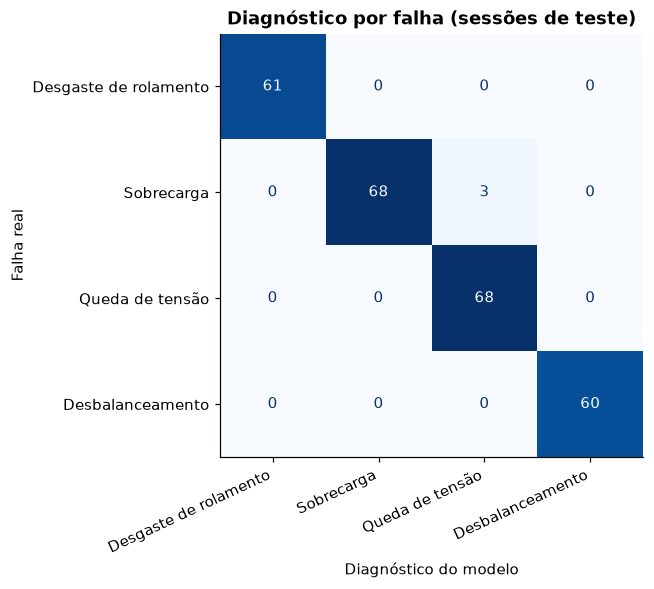

In [11]:
_, resultado = diagnosticos["Árvore de decisão"]
fig, eixo = plt.subplots(figsize=(6.2, 5))
ConfusionMatrixDisplay.from_predictions(
    resultado["real"].map(NOMES),
    resultado["previsto"].map(NOMES),
    labels=[NOMES[f] for f in FALHAS],
    cmap="Blues",
    ax=eixo,
    colorbar=False,
)
eixo.set_xlabel("Diagnóstico do modelo")
eixo.set_ylabel("Falha real")
eixo.grid(False)
plt.setp(eixo.get_xticklabels(), rotation=25, ha="right")
eixo.set_title("Diagnóstico por falha (sessões de teste)", fontweight="bold")
salvar(fig, "05_matriz_confusao")

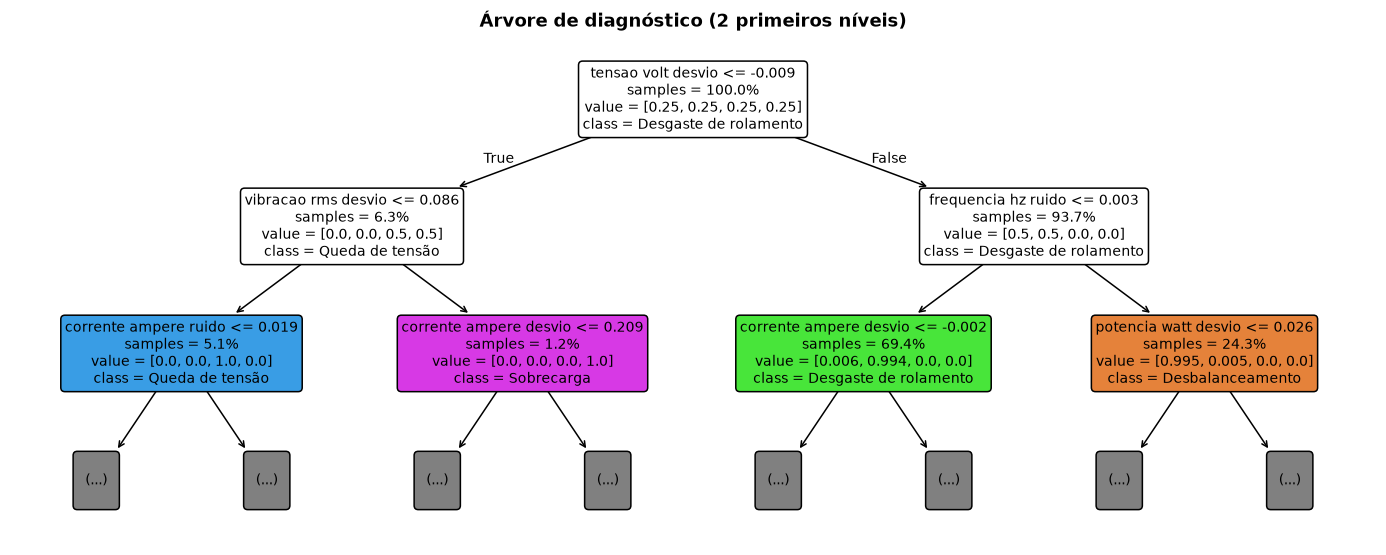

In [12]:
fig, eixo = plt.subplots(figsize=(16, 6))
plot_tree(
    arvore,
    max_depth=2,
    feature_names=[c.replace("_", " ") for c in COLUNAS_DIAGNOSTICO],
    class_names=[NOMES[c] for c in arvore.classes_],
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    fontsize=9,
    ax=eixo,
)
eixo.set_title("Árvore de diagnóstico (2 primeiros níveis)", fontweight="bold")
salvar(fig, "06_arvore")

|--- tensao_volt_desvio <= -0.009
|   |--- vibracao_rms_desvio <= 0.086
|   |   |--- corrente_ampere_ruido <= 0.019
|   |   |   |--- class: queda_tensao
|   |   |--- corrente_ampere_ruido >  0.019
|   |   |   |--- class: queda_tensao
|   |--- vibracao_rms_desvio >  0.086
|   |   |--- corrente_ampere_desvio <= 0.209
|   |   |   |--- class: sobrecarga
|   |   |--- corrente_ampere_desvio >  0.209
|   |   |   |--- class: sobrecarga
|--- tensao_volt_desvio >  -0.009
|   |--- frequencia_hz_ruido <= 0.003
|   |   |--- corrente_ampere_desvio <= -0.002
|   |   |   |--- truncated branch of depth 3
|   |   |--- corrente_ampere_desvio >  -0.002
|   |   |   |--- truncated branch of depth 4
|   |--- frequencia_hz_ruido >  0.003
|   |   |--- potencia_watt_desvio <= 0.026
|   |   |   |--- truncated branch of depth 3
|   |   |--- potencia_watt_desvio >  0.026
|   |   |   |--- truncated branch of depth 2



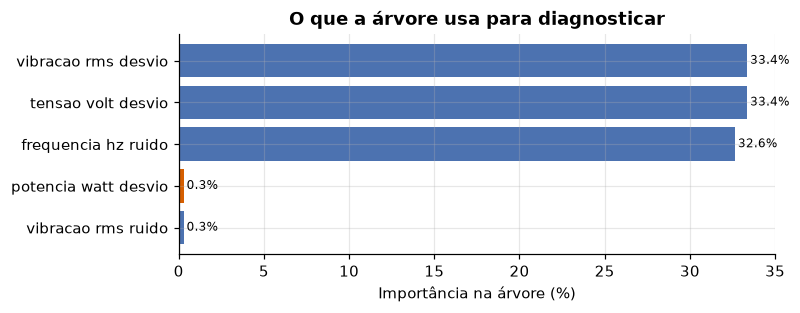

In [13]:
importancia = pd.Series(
    arvore.feature_importances_, index=COLUNAS_DIAGNOSTICO
).sort_values()
importancia = importancia[importancia >= 0.001]

fig, eixo = plt.subplots(figsize=(7, 0.32 * len(importancia) + 1))
barras = eixo.barh(
    [c.replace("_", " ") for c in importancia.index],
    importancia.values * 100,
    color=[
        "#D55E00" if c.startswith("potencia") else "#4c72b0" for c in importancia.index
    ],
)
eixo.bar_label(barras, fmt="%.1f%%", fontsize=8, padding=2)
eixo.set_xlabel("Importância na árvore (%)")
eixo.set_title("O que a árvore usa para diagnosticar", fontweight="bold")
salvar(fig, "07_importancia")

print(
    export_text(
        arvore, feature_names=list(COLUNAS_DIAGNOSTICO), max_depth=2, decimals=3
    )
)

## 6. Prognóstico: quando a vibração passa do limite?

No desgaste de rolamento a vibração sobe aos poucos. Ajustando uma **regressão** à vibração dos últimos minutos, dá para projetar quando ela vai cruzar o **limite (o dobro do normal)**, e essa estimativa vira a data da manutenção preditiva.

A previsão é feita quando a vibração passa de **+25%** e de **+50%**, e comparada com o momento real do cruzamento. Foram testadas uma **reta** e uma regressão com **termo quadrático** (y = a + b·t + c·t², que continua sendo regressão *linear*, pois é linear nos coeficientes), com janelas de 1 a 3 minutos.

In [14]:
linhas = []
for grau, nome in ((1, "Reta"), (2, "Com termo quadrático")):
    for janela_min in (1, 2, 3):
        r, previsoes = avaliar_prognostico(
            dados_teste,
            treinar.LIMITE_VIBRACAO,
            janela=janela_min * LEITURAS_POR_MINUTO,
            grau=grau,
        )
        for marco, m in r["por_marco"].items():
            g = previsoes[previsoes["marco"] == float(marco)].dropna()
            linhas.append(
                {
                    "regressão": nome,
                    "janela (min)": janela_min,
                    "previsão em": f"+{float(marco):.0%}",
                    "erro médio (min)": m["erro_absoluto_medio_min"],
                    "viés (min)": (g["previsto_min"] - g["real_min"]).mean(),
                }
            )
comparacao = pd.DataFrame(linhas)
comparacao.pivot_table(
    index=["regressão", "janela (min)"],
    columns="previsão em",
    values=["erro médio (min)", "viés (min)"],
).round(2)

erro médio (min)       viés (min)      
previsão em                                   +25%  +50%       +25%  +50%
regressão            janela (min)                                        
Com termo quadrático 1                        0.99  0.61      -0.96 -0.61
                     2                        0.62  0.43      -0.61 -0.37
                     3                        0.44  0.38      -0.31 -0.38
Reta                 1                        0.55  0.23       0.46 -0.10
                     2                        2.40  0.37       2.40  0.36
                     3                        6.37  1.44       6.37  1.44

A **reta com janela de 3 min** erra feio e sempre **para mais tarde** (viés positivo): o desgaste acelera, e a reta não acompanha. O **termo quadrático** acompanha a curvatura, tem o menor erro e, quando erra, erra **para mais cedo** (viés negativo). Para manutenção, esse é o lado seguro: melhor agendar um pouco antes do que depois.

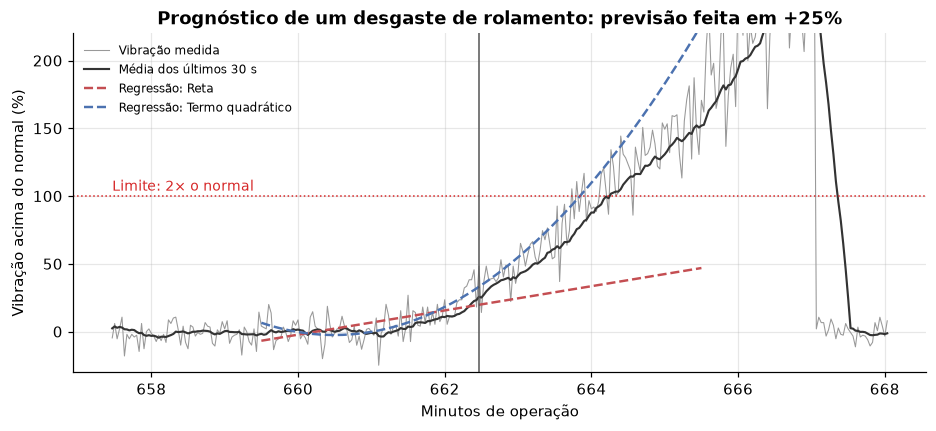

In [15]:
_, previsoes = avaliar_prognostico(dados_teste, treinar.LIMITE_VIBRACAO)
exemplo = (
    previsoes[previsoes["marco"] == 0.25]
    .sort_values("real_min")
    .iloc[len(previsoes) // 4]
)
ev = dados_teste[dados_teste["evento"] == exemplo["evento"]]
grupo = dados_teste[
    (dados_teste["sessao"] == ev["sessao"].iat[0])
    & (dados_teste["maquina_id"] == ev["maquina_id"].iat[0])
]
agora = ev.index[np.argmax(ev["vibracao_rms_desvio"].to_numpy() >= 0.25)]
janela = dados_teste.loc[agora - 89 : agora, "vibracao_relativa"].to_numpy()
inicio_min = dados_teste.at[agora - 89, "posicao"] / LEITURAS_POR_MINUTO

contexto = grupo.loc[agora - 150 : ev.index[-1] + 30]
fig, eixo = plt.subplots(figsize=(10, 4))
eixo.plot(
    contexto["posicao"] / LEITURAS_POR_MINUTO,
    contexto["vibracao_relativa"] * 100,
    color="#999",
    lw=0.7,
    label="Vibração medida",
)
eixo.plot(
    contexto["posicao"] / LEITURAS_POR_MINUTO,
    contexto["vibracao_rms_desvio"] * 100,
    color="#333",
    lw=1.4,
    label="Média dos últimos 30 s",
)
t_futuro = np.linspace(0, 6, 300)
for grau, cor, nome in ((1, "#c44e52", "Reta"), (2, "#4c72b0", "Termo quadrático")):
    reta = ajustar_tendencia(janela, grau)
    eixo.plot(
        inicio_min + t_futuro,
        reta.predict(_termos(t_futuro, grau)) * 100,
        "--",
        color=cor,
        lw=1.6,
        label=f"Regressão: {nome}",
    )
eixo.axhline(treinar.LIMITE_VIBRACAO * 100, color="#d62728", lw=1, ls=":")
eixo.text(
    contexto["posicao"].iat[0] / LEITURAS_POR_MINUTO,
    treinar.LIMITE_VIBRACAO * 100 + 4,
    "Limite: 2× o normal",
    color="#d62728",
    fontsize=9,
)
eixo.axvline(dados_teste.at[agora, "posicao"] / LEITURAS_POR_MINUTO, color="#555", lw=1)
eixo.set_ylim(-30, 220)
eixo.set_xlabel("Minutos de operação")
eixo.set_ylabel("Vibração acima do normal (%)")
eixo.legend(frameon=False, fontsize=8, loc="upper left")
eixo.set_title(
    "Prognóstico de um desgaste de rolamento: previsão feita em +25%", fontweight="bold"
)
salvar(fig, "08_prognostico")

## 7. Quanto antes o problema é percebido?

Para o desgaste, a pergunta prática é: **quantos minutos antes de a vibração passar do limite o sistema já tinha alertado?**

Em 100% dos desgastes o alerta veio antes do limite (mediana de 1.7 min de antecedência).


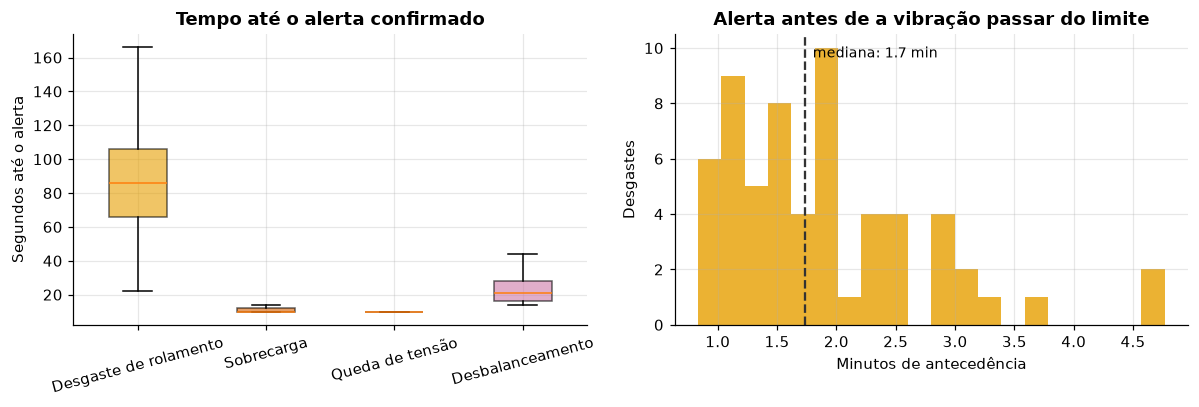

In [16]:
eventos_if = eventos["Isolation Forest"]
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
dados_atraso = [
    eventos_if.loc[eventos_if["cenario"] == f, "atraso_s"].dropna() for f in FALHAS
]
caixa = a.boxplot(
    dados_atraso,
    tick_labels=[NOMES[f] for f in FALHAS],
    patch_artist=True,
    showfliers=False,
)
for patch, falha in zip(caixa["boxes"], FALHAS):
    patch.set_facecolor(CORES[falha])
    patch.set_alpha(0.6)
a.set_ylabel("Segundos até o alerta")
a.set_title("Tempo até o alerta confirmado", fontweight="bold")
plt.setp(a.get_xticklabels(), rotation=15)

antecedencia = []
desvio = dados_teste["vibracao_rms_desvio"].to_numpy()
for evento, ev in dados_teste[dados_teste["cenario"] == "desgaste_rolamento"].groupby(
    "evento"
):
    idx = ev.index.to_numpy()
    cruzou = idx[desvio[idx] >= treinar.LIMITE_VIBRACAO]
    alertou = idx[alertas_teste[idx]]
    if len(cruzou) and len(alertou):
        antecedencia.append((cruzou[0] - alertou[0]) / LEITURAS_POR_MINUTO)
antecedencia = pd.Series(antecedencia)
b.hist(antecedencia, bins=20, color=CORES["desgaste_rolamento"], alpha=0.8)
b.axvline(antecedencia.median(), color="#333", ls="--")
b.text(
    antecedencia.median(),
    b.get_ylim()[1] * 0.92,
    f"  mediana: {antecedencia.median():.1f} min",
    fontsize=9,
)
b.set_xlabel("Minutos de antecedência")
b.set_ylabel("Desgastes")
b.set_title("Alerta antes de a vibração passar do limite", fontweight="bold")
fig.tight_layout()
salvar(fig, "09_antecedencia")
print(
    f"Em {(antecedencia > 0).mean():.0%} dos desgastes o alerta veio antes do limite "
    f"(mediana de {antecedencia.median():.1f} min de antecedência)."
)

## 8. O modelo salvo

O script `python -m ml.treinar` executa exatamente estes passos e salva o resultado em `ml/modelos/modelo_falhas.joblib`, que a API vai carregar na fase 3. As métricas abaixo são as gravadas junto com ele.

In [17]:
salvo = ModeloFalhas.carregar("ml/modelos/modelo_falhas.joblib")
d, g, p = (salvo.metricas[k] for k in ("deteccao", "diagnostico", "prognostico"))
print(f"Treinado em {salvo.treinado_em} com scikit-learn {salvo.versao_sklearn}")
print(
    f"Detecção:    {d['taxa_deteccao']:.1%} das {d['falhas']} falhas · atraso mediano {d['atraso_mediano_s']:.0f} s · {d['alarmes_falsos_por_maquina_dia']:.2f} alarmes falsos por máquina-dia"
)
print(f"Diagnóstico: {g['acuracia']:.1%} de acerto")
print(
    f"Prognóstico: erro médio de {p['erro_absoluto_medio_min']:.2f} min (viés {p['erro_medio_min']:+.2f} min)"
)

Treinado em 2026-11-17T05:52:24+00:00 com scikit-learn 1.9.1
Detecção:    99.6% das 261 falhas · atraso mediano 12 s · 0.66 alarmes falsos por máquina-dia
Diagnóstico: 98.8% de acerto
Prognóstico: erro médio de 0.41 min (viés -0.35 min)


## 9. Limitações

É importante ser honesto sobre o que estes números significam:

- **Os dados são simulados.** As falhas seguem fórmulas que nós mesmos escrevemos. Para o resultado não ser só "o modelo decorou a fórmula", cada falha tem intensidade e duração sorteadas, e o teste usa sessões que o modelo nunca viu. Ainda assim, numa fábrica real os sinais seriam mais sujos e as falhas mais variadas; o esperado é um desempenho menor.
- **O tempo está comprimido.** Um desgaste aqui leva minutos; na vida real, semanas. A lógica (detectar a tendência e projetar o cruzamento) é a mesma, só a escala muda.
- **A linha de base precisa de histórico.** A máquina precisa de ~8 min de operação (aquecimento) antes de ser avaliada, e uma falha muito longa acabaria "virando o novo normal" depois de 30 min.
- **O detector não depende dos tipos simulados**, mas o diagnóstico só conhece as 4 falhas do treino. Uma falha nova seria detectada, porém diagnosticada como a mais parecida.